## Model 2: compiled DBQA circuits for Er$^{3+}$:LiYF$_4$

As for Model 1 (`Example_3_compiled_DBQA_Ce_YAG.ipynb`), we compile the evolution oracle $e^{-it\hat H}$ into CNOT ladders (`PauliCompiledHamiltonian`) and run the circuit version of DBQA: DB-DOI ground-state preparation with `GroupCommutatorIteration`.

At 9 qubits one compiled Trotter step has about $10^6$ CNOTs, so the circuits are not built gate by gate (several million gate objects). Instead:
- `compiled_trotter_unitary` computes the **exact unitary of the compiled gate sequence** term by term (each CNOT ladder equals $e^{-i\theta P}$ exactly; the tests check the whole sequence against the explicit circuits at 3 qubits),
- `compiled_trotter_depth` computes the **exact depth** of the compiled circuit by scheduling the same gate sequence (checked against `Circuit.depth` in the tests),
- `CompiledUnitaryHamiltonian` uses the compiled unitary as the evolution oracle of `GroupCommutatorIteration`, i.e. simulates the compiled DB-DOI circuits up to the global phase of the identity term.

The full run takes about an hour on a laptop; the compiled Trotter steps are cached in `simulation_results/Er_LiYF4_trotter_steps.npz` (not under version control).

In [1]:
import os
import csv
import logging
import pickle

import numpy as np
import matplotlib.pyplot as plt

from qibo import set_backend
from qibo.config import log

from pycf import cfl
from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

# PyCF source tree with the bundled matrix-element bases (examples/*/matel)
os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))

set_backend("numpy")
log.setLevel(logging.ERROR)
os.makedirs("pdfs_figures", exist_ok=True)
os.makedirs("simulation_results", exist_ok=True)

import sys
import time
from copy import deepcopy
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp

from qibo import gates, hamiltonians
from qibo.symbols import Z
from scipy.linalg import expm
from scipy.sparse.csgraph import connected_components

sys.path.append(os.path.abspath("../../src"))
from db_doi.group_commutator_iteration import GroupCommutatorIteration, DoubleBracketRotationApproximationType

[Qibo 0.2.14|INFO|2026-10-16 12:22:41]: Using numpy backend on /CPU:0


In [2]:
f11cf = ImportSLJM(pycf_matel_path("f11cf", "eryso"))
coeff = er_liyf4_pycf_coeff(ER_LIYF4_FREE_ION_REFIT)
tensors = [getattr(f11cf, name) for name in coeff]

energy_unit = 20000.0  # cm^-1, so that the norm of the embedded Hamiltonian is O(1)
h, n_physical = crystal_field_hamiltonian(tensors, coeff, energy_unit=energy_unit)
h_matrix = h.backend.to_numpy(h.matrix)
energies = np.linalg.eigvalsh(h_matrix)

# levels: Kramers doublets, grouped with 1e-3 cm^-1
tol_doublets = 1e-3 / energy_unit
doublets = group_levels(energies, tol_doublets)
# manifolds: clusters separated by more than 300 cm^-1, larger than every gap inside the ground multiplet
tol_manifolds = 300.0 / energy_unit
manifolds = group_levels(energies, tol_manifolds)
# clusters: levels closer than 1 cm^-1 merged, for the close pairs (e.g. the two lowest levels, 0.36 cm^-1 apart)
tol_clusters = 1.0 / energy_unit
clusters = group_levels(energies, tol_clusters)
inside, between = check_grouping_tolerance(energies, tol_doublets)
assert inside < tol_doublets < between
decomposition = pauli_decomposition(h_matrix)
identity = decomposition["I" * h.nqubits]
traceless = h_matrix - identity * np.eye(2**h.nqubits)
_, vectors_exact = np.linalg.eigh(h_matrix)
ground_doublet = vectors_exact[:, doublets[0]]
ground_multiplet = vectors_exact[:, manifolds[0]]
print(f"{len(decomposition)} Pauli strings, norm of the traceless part {np.linalg.norm(traceless, 2):.2f}")

93184 Pauli strings, norm of the traceless part 3.07


#### Trotter error of the compiled oracle

DB-DOI calls the oracle for durations $\sqrt{s}$ with $s \le 1$ (see below), so up to $t = 1$. We compute the exact unitary of one compiled Trotter step $S(\delta t)$ for several step sizes (in parallel processes) and the error $\|S(\delta t)^n - e^{-it(\hat H - c_I)}\|$ for durations $t = n\,\delta t \le 1$.

In [3]:
t_max = 1.0
configurations = [(1, t_max / n) for n in (1, 4, 16)] + [(2, t_max / n) for n in (1, 2, 4, 8, 16)]
cache = "simulation_results/Er_LiYF4_trotter_steps.npz"
key = lambda config: f"order{config[0]}_dt{config[1]:.6f}"
stored = dict(np.load(cache)) if os.path.exists(cache) else {}
missing = [config for config in configurations if key(config) not in stored]
if missing:
    os.environ["OPENBLAS_NUM_THREADS"] = "2"
    start = time.time()
    with ProcessPoolExecutor(max_workers=len(missing), mp_context=mp.get_context("spawn")) as pool:
        futures = {config: pool.submit(compiled_trotter_unitary, decomposition, config[1], config[0]) for config in missing}
        for config, future in futures.items():
            stored[key(config)] = future.result()
    np.savez_compressed(cache, **stored)
    print(f"computed {len(missing)} compiled step unitaries in {(time.time() - start) / 60:.0f} min")
step_unitaries = {config: stored[key(config)] for config in configurations}

depths = {}
def depth(ts_order, n):
    if (ts_order, n) not in depths:
        depths[(ts_order, n)] = compiled_trotter_depth(decomposition, ts_order, n)
    return depths[(ts_order, n)]

trotter_table = []
print(f"{'order':>5s} {'dt':>8s} {'steps n':>7s} {'t = n dt':>8s} {'error':>9s} {'CNOT':>10s} {'depth':>10s}")
for (ts_order, dt), step in step_unitaries.items():
    n_max = int(round(t_max / dt))
    for n in sorted({1, n_max // 4, n_max // 2, n_max} - {0}):
        t = n * dt
        error = np.linalg.norm(np.linalg.matrix_power(step, n) - expm(-1j * t * traceless), 2)
        row = dict(ts_order=ts_order, dt=dt, steps=n, t=t, error=error,
                   cnot=n * trotter_cnot_count(decomposition, ts_order), depth=depth(ts_order, n))
        trotter_table.append(row)
        print(f"{ts_order:5d} {dt:8.4f} {n:7d} {t:8.4f} {error:9.1e} {row['cnot']:10d} {row['depth']:10d}")

computed 8 compiled step unitaries in 18 min
order       dt steps n t = n dt     error       CNOT      depth


    1   1.0000       1   1.0000   9.7e-01    1073026    1323115


    1   0.2500       1   0.2500   7.7e-02    1073026    1323115


    1   0.2500       2   0.5000   1.5e-01    2146052    2646223


    1   0.2500       4   1.0000   2.6e-01    4292104    5292439


...

    2   0.1250       8   1.0000   5.4e-03   17168288   21169704


    2   0.0625       1   0.0625   1.6e-04    2146036    2646213


    2   0.0625       4   0.2500   5.9e-04    8584144   10584852


    2   0.0625       8   0.5000   1.0e-03   17168288   21169704


    2   0.0625      16   1.0000   1.4e-03   34336576   42339408


We use the second-order formula with the smallest number of steps whose error at $t = 1$ is at most $5\times10^{-3}$, as for Model 1 (or the most accurate one computed if none reaches it).

In [4]:
candidates = [r for r in trotter_table if r["ts_order"] == 2 and np.isclose(r["t"], t_max)]
accurate = [r for r in candidates if r["error"] <= 5e-3]
chosen = min(accurate, key=lambda r: r["steps"]) if accurate else min(candidates, key=lambda r: r["error"])
TS_ORDER, TROTTER_STEPS = 2, chosen["steps"]
oracle_cnot = TROTTER_STEPS * trotter_cnot_count(decomposition, TS_ORDER)
oracle_depth = depth(TS_ORDER, TROTTER_STEPS)
print(f"oracle: second order, {TROTTER_STEPS} steps, error at t = {t_max}: {chosen['error']:.1e}; {oracle_cnot} CNOTs, depth {oracle_depth} per call")

oracle: second order, 16 steps, error at t = 1.0: 1.4e-03; 34336576 CNOTs, depth 42339408 per call


#### Symmetry sectors and reference states

In the $|SLJM\rangle$ basis the $D_{2d}$ Hamiltonian is block diagonal: the free ion conserves $M_J$ and the crystal field ($q = 0, \pm4$) changes it by 4, so the basis splits into sectors that the Hamiltonian never connects. A diagonal operator $D$ preserves them too, so **DB-DOI cannot leave the sector of its reference state**. We find the sectors from the sparsity pattern of $\hat H$ alone (connected components), merge Kramers-partner sectors (identical sets of diagonal entries), and start DB-DOI from the basis state with the lowest diagonal energy in each sector. The ground doublet lies in one pair of sectors; in the other the lowest level is the next doublet.

In [5]:
n_components, labels = connected_components(np.abs(h_matrix) > 1e-12)
diagonal = np.real(np.diag(h_matrix))
sectors = [np.nonzero(labels == c)[0] for c in range(n_components) if np.sum(labels == c) > 1]
distinct = []
for members in sectors:
    if not any(len(members) == len(other) and np.allclose(np.sort(diagonal[members]), np.sort(diagonal[other])) for other in distinct):
        distinct.append(members)
print(f"{n_components} components: {len(sectors)} sectors of sizes {[len(m) for m in sectors]} and {n_components - len(sectors)} uncoupled padding states; {len(distinct)} distinct up to Kramers symmetry")

def state_report(circuit, sector_ground):
    state = h.backend.to_numpy(circuit().state())
    energy = np.real(state.conj() @ h_matrix @ state)
    return dict(
        energy_error=energy_unit * (energy - energies[0]),
        ground_fidelity=np.sum(np.abs(ground_doublet.conj().T @ state) ** 2),
        sector_fidelity=np.abs(sector_ground.conj() @ state) ** 2,
        multiplet_fidelity=np.sum(np.abs(ground_multiplet.conj().T @ state) ** 2),
    )

references = []
for members in distinct:
    index = int(members[np.argmin(diagonal[members])])
    block_energies, block_vectors = np.linalg.eigh(h_matrix[np.ix_(members, members)])
    sector_ground = np.zeros(2**h.nqubits, dtype=complex)
    sector_ground[members] = block_vectors[:, 0]
    references.append(dict(index=index, members=members, sector_ground=sector_ground,
                           sector_ground_energy=energy_unit * (block_energies[0] - energies[0])))
    report = state_report(basis_state_circuit(h.nqubits, index), sector_ground)
    print(f"reference |{format(index, '09b')}> ({index}): lowest level of its sector {references[-1]['sector_ground_energy']:.2f} cm^-1 above the ground; {report}")

152 components: 4 sectors of sizes [91, 91, 91, 91] and 148 uncoupled padding states; 2 distinct up to Kramers symmetry


reference |010011101> (157): lowest level of its sector 0.36 cm^-1 above the ground; {'energy_error': 893.4294551298372, 'ground_fidelity': 1.9202092433759415e-24, 'sector_fidelity': 0.23236210851648906, 'multiplet_fidelity': 0.9707138028592279}


reference |011101110> (238): lowest level of its sector -0.00 cm^-1 above the ground; {'energy_error': 907.0435486917416, 'ground_fidelity': 0.04880942356512649, 'sector_fidelity': 0.048809423564764615, 'multiplet_fidelity': 0.9708737732363822}


#### DB-DOI with an ideal oracle

At each step the diagonal operator is a magnetic field chosen among $\pm\sum_i Z_i$ and $\pm Z_i$, and the step $s \in [10^{-3}, 1]$ on a grid, minimising the energy. Besides the energy we report the fidelity with the lowest level of the sector (the state DB-DOI can reach), with the ground Kramers doublet, and with the whole ground multiplet $^4I_{15/2}$ (16 states), which separates the free-ion and crystal-field scales as in `Example_6`.

In [6]:
NSTEPS_DOI = 5
step_grid = np.linspace(1e-3, 1.0, 20)
fields = [np.ones(h.nqubits), -np.ones(h.nqubits)] + [s * np.eye(h.nqubits)[i] for i in range(h.nqubits) for s in (1, -1)]
d_candidates = [hamiltonians.SymbolicHamiltonian(sum(float(b) * Z(q) for q, b in enumerate(field) if b != 0), nqubits=h.nqubits) for field in fields]
oracle = ExactEvolutionHamiltonian(h_matrix)

def oracle_queries(circuit):
    return sum(1 for g in circuit.queue if isinstance(g, gates.Unitary) and len(g.qubits) == h.nqubits)

doi_histories = []
for reference in references:
    gci = GroupCommutatorIteration(
        h=deepcopy(oracle),
        preparation_circuit=basis_state_circuit(h.nqubits, reference["index"]),
        double_bracket_rotation_approximation_type=DoubleBracketRotationApproximationType.group_commutator_reduced,
    )
    history = [dict(state_report(gci.preparation_circuit, reference["sector_ground"]), queries=0, step=None, field=None, depth=gci.preparation_circuit.depth)]
    print(f"reference {reference['index']}:")
    for k in range(NSTEPS_DOI):
        start = time.time()
        best = None
        for j, d in enumerate(d_candidates):
            s, loss, _, _ = gci.choose_step(d, step_grid=step_grid)
            if best is None or loss < best[1]:
                best = (s, loss, j)
        gci(best[0], d_candidates[best[2]])
        circuit = gci.preparation_circuit
        history.append(dict(state_report(circuit, reference["sector_ground"]), queries=oracle_queries(circuit), step=best[0], field=best[2], depth=circuit.depth))
        r = history[-1]
        print(f"  k={k+1}: s={r['step']:.3f}, D #{r['field']}, dE={r['energy_error']:.2f} cm^-1, 1-F(sector ground)={1 - r['sector_fidelity']:.2e}, "
              f"1-F(ground doublet)={1 - r['ground_fidelity']:.2e}, 1-F(4I15/2)={1 - r['multiplet_fidelity']:.2e}, queries={r['queries']}, {time.time()-start:.0f}s")
    doi_histories.append(history)

reference 157:


  k=1: s=0.422, D #1, dE=113.52 cm^-1, 1-F(sector ground)=7.61e-01, 1-F(ground doublet)=1.00e+00, 1-F(4I15/2)=1.60e-03, queries=1, 64s


  k=2: s=0.369, D #14, dE=93.52 cm^-1, 1-F(sector ground)=7.60e-01, 1-F(ground doublet)=1.00e+00, 1-F(4I15/2)=8.64e-04, queries=4, 57s


  k=3: s=0.632, D #4, dE=89.72 cm^-1, 1-F(sector ground)=7.59e-01, 1-F(ground doublet)=1.00e+00, 1-F(4I15/2)=4.93e-04, queries=13, 125s


  k=4: s=0.054, D #0, dE=87.77 cm^-1, 1-F(sector ground)=7.58e-01, 1-F(ground doublet)=1.00e+00, 1-F(4I15/2)=4.16e-04, queries=40, 329s


...

  k=1: s=0.685, D #1, dE=121.20 cm^-1, 1-F(sector ground)=9.50e-01, 1-F(ground doublet)=9.50e-01, 1-F(4I15/2)=1.20e-03, queries=1, 21s


  k=2: s=0.316, D #12, dE=107.55 cm^-1, 1-F(sector ground)=9.49e-01, 1-F(ground doublet)=9.49e-01, 1-F(4I15/2)=6.74e-04, queries=4, 20s


  k=3: s=0.422, D #4, dE=103.33 cm^-1, 1-F(sector ground)=9.49e-01, 1-F(ground doublet)=9.49e-01, 1-F(4I15/2)=4.43e-04, queries=13, 48s


  k=4: s=0.422, D #0, dE=99.71 cm^-1, 1-F(sector ground)=9.49e-01, 1-F(ground doublet)=9.49e-01, 1-F(4I15/2)=3.02e-04, queries=40, 127s


  k=5: s=0.527, D #2, dE=97.66 cm^-1, 1-F(sector ground)=9.48e-01, 1-F(ground doublet)=9.48e-01, 1-F(4I15/2)=2.11e-04, queries=121, 393s


#### Compiled circuits

For the sector that contains the ground doublet we replay the same steps and magnetic fields with the compiled oracle (`CompiledUnitaryHamiltonian`, the exact unitary of the compiled CNOT circuit) for the first steps. All two-qubit gates are inside the oracle calls, so the CNOT count is the number of queries times the CNOTs per call. Each oracle call covers all 9 qubits, so the depth of the compiled circuit is at most the depth of the ideal-oracle circuit with every oracle gate replaced by the oracle depth.

In [7]:
NSTEPS_COMPILED = 2
ground_sector = int(np.argmin([reference["sector_ground_energy"] for reference in references]))
reference = references[ground_sector]
gci_compiled = GroupCommutatorIteration(
    h=CompiledUnitaryHamiltonian(h_matrix, trotter_steps=TROTTER_STEPS, ts_order=TS_ORDER),
    preparation_circuit=basis_state_circuit(h.nqubits, reference["index"]),
    double_bracket_rotation_approximation_type=DoubleBracketRotationApproximationType.group_commutator_reduced,
)
compiled_history = [state_report(gci_compiled.preparation_circuit, reference["sector_ground"])]
for k in range(NSTEPS_COMPILED):
    start = time.time()
    r = doi_histories[ground_sector][k + 1]
    gci_compiled(r["step"], d_candidates[r["field"]])
    compiled_history.append(state_report(gci_compiled.preparation_circuit, reference["sector_ground"]))
    c = compiled_history[-1]
    print(f"k={k+1}: dE={c['energy_error']:.3f} cm^-1 (ideal {r['energy_error']:.3f}), 1-F(ground doublet)={1 - c['ground_fidelity']:.3e} (ideal {1 - r['ground_fidelity']:.3e}), {time.time()-start:.0f}s")

k=1: dE=120.918 cm^-1 (ideal 121.205), 1-F(ground doublet)=9.496e-01 (ideal 9.496e-01), 205s


k=2: dE=107.518 cm^-1 (ideal 107.546), 1-F(ground doublet)=9.493e-01 (ideal 9.493e-01), 242s


In [8]:
for reference, history in zip(references, doi_histories):
    print(f"reference {reference['index']} (sector ground {reference['sector_ground_energy']:.2f} cm^-1):")
    print(f"{'k':>4s} {'dE (cm^-1)':>11s} {'1-F sector':>11s} {'1-F doublet':>11s} {'1-F 4I15/2':>11s} {'queries':>8s} {'CNOT':>12s} {'depth <=':>13s}")
    for k, r in enumerate(history):
        cnot = r["queries"] * oracle_cnot
        depth_bound = r["depth"] + r["queries"] * (oracle_depth - 1)
        print(f"{k:4d} {r['energy_error']:11.2f} {1 - r['sector_fidelity']:11.2e} {1 - r['ground_fidelity']:11.2e} {1 - r['multiplet_fidelity']:11.2e} {r['queries']:8d} {cnot:12d} {depth_bound:13d}")

reference 157 (sector ground 0.36 cm^-1):
   k  dE (cm^-1)  1-F sector 1-F doublet  1-F 4I15/2  queries         CNOT      depth <=
   0      893.43    7.68e-01    1.00e+00    2.93e-02        0            0             1
   1      113.52    7.61e-01    1.00e+00    1.60e-03        1     34336576      42339415
   2       93.52    7.60e-01    1.00e+00    8.64e-04        4    137346304     169357657
   3       89.72    7.59e-01    1.00e+00    4.93e-04       13    446375488     550412379
   4       87.77    7.58e-01    1.00e+00    4.16e-04       40   1373463040    1693576549
   5       86.22    7.57e-01    1.00e+00    2.61e-04      121   4154725696    5123069059
reference 238 (sector ground -0.00 cm^-1):
   k  dE (cm^-1)  1-F sector 1-F doublet  1-F 4I15/2  queries         CNOT      depth <=
   0      907.04    9.51e-01    9.51e-01    2.91e-02        0            0             1
   1      121.20    9.50e-01    9.50e-01    1.20e-03        1     34336576      42339415
   2      107.55    9.49e

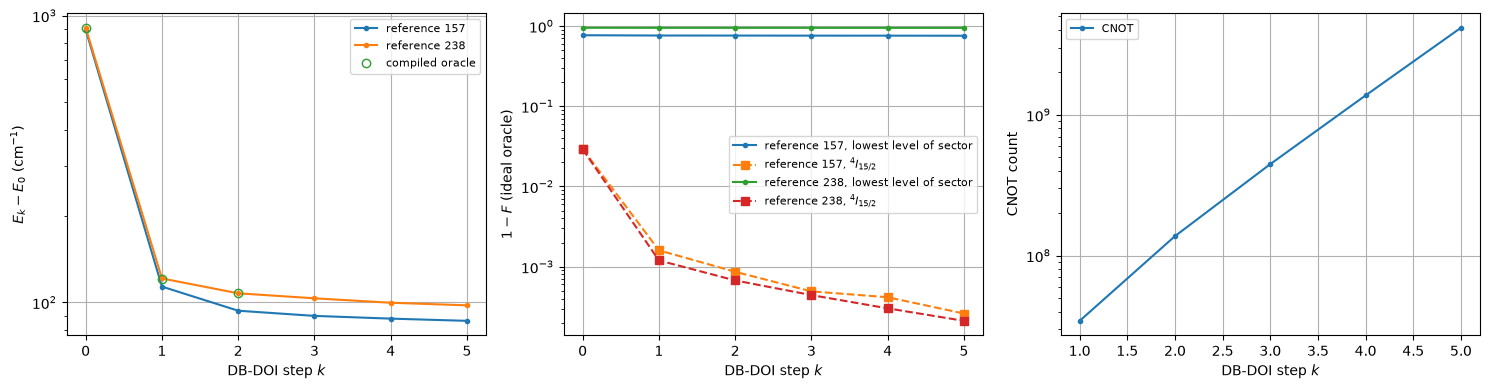

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for reference, history in zip(references, doi_histories):
    ks = np.arange(len(history))
    label = f"reference {reference['index']}"
    axes[0].semilogy(ks, [r["energy_error"] for r in history], ".-", label=label)
    axes[1].semilogy(ks, [1 - r["sector_fidelity"] for r in history], ".-", label=f"{label}, lowest level of sector")
    axes[1].semilogy(ks, [1 - r["multiplet_fidelity"] for r in history], "s--", label=f"{label}, $^4I_{{15/2}}$")
axes[0].semilogy(np.arange(len(compiled_history)), [r["energy_error"] for r in compiled_history], "o", mfc="none", label="compiled oracle")
axes[0].set_ylabel(r"$E_k - E_0$ (cm$^{-1}$)")
axes[1].set_ylabel(r"$1-F$ (ideal oracle)")
history = doi_histories[ground_sector]
axes[2].semilogy(np.arange(1, len(history)), [r["queries"] * oracle_cnot for r in history[1:]], ".-", label="CNOT")
axes[2].set_ylabel("CNOT count")
for ax in axes:
    ax.set_xlabel("DB-DOI step $k$"); ax.grid(True); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("pdfs_figures/Er_LiYF4_compiled_DB_DOI.pdf", bbox_inches="tight")
plt.show()

#### Saving the data

In [10]:
with open(f"simulation_results/Er_LiYF4_compiled_DB_DOI_L_{h.nqubits}.pickle", "wb") as file:
    pickle.dump(
        dict(
            trotter_table=trotter_table,
            ts_order=TS_ORDER,
            trotter_steps=TROTTER_STEPS,
            oracle_cnot=oracle_cnot,
            oracle_depth=oracle_depth,
            references=[dict(index=r["index"], sector_size=len(r["members"]), sector_ground_energy=r["sector_ground_energy"]) for r in references],
            ground_sector=ground_sector,
            doi_histories=doi_histories,
            compiled_history=compiled_history,
        ),
        file,
    )